# TRƯỜNG ĐẠI HỌC THỦY LỢI
## KHOA CÔNG NGHỆ THÔNG TIN • BỘ MÔN TRÍ TUỆ NHÂN TẠO
### BÀI THỰC HÀNH LAB 4 (CSE457): TỔNG HỢP TIẾNG NÓI (TEXT-TO-SPEECH)
**Chủ đề:** Từ kiến trúc TTS, ghép nối và unit selection đến tổng hợp tham số HMM và TTS học sâu

---
### Mục tiêu bài học:
1. Nắm vững kiến trúc tổng quát của hệ Text-to-Speech: $\text{Text Analysis} \rightarrow \text{Phonetic Analysis} \rightarrow \text{Prosodic Analysis} \rightarrow \text{Speech Synthesis Backend} \rightarrow \text{Waveform}$.
2. Thực hiện Text Normalization cho miền hẹp (đọc chuỗi số, chuẩn hóa dấu câu).
3. Xây dựng bộ Unit Inventory và thực thi Baseline Concatenative Synthesis (ghép nối thô).
4. Áp dụng thuật toán Unit Selection bằng Quy hoạch động (Viterbi Search) tối ưu hóa hàm mục tiêu:
   $$\theta^* = \arg\min_{\theta_1 \dots \theta_J} \left[ \sum_{j=1}^J C_{\text{target}}(\theta_j, t_j) + \lambda \sum_{j=1}^{J-1} C_{\text{join}}(\theta_j, \theta_{j+1}) \right]$$
5. Triệt tiêu hiện tượng gián đoạn biên (click, phase mismatch) bằng Cross-fade / Overlap-Add (OLA).
6. Nghiên cứu mô hình Nguồn - Bộ lọc (Source-Filter Model), đo đạc chu kỳ pitch $N_p$ để kiểm chứng $F_0 \approx F_s / N_p$, và can thiệp Prosody (Time-stretch WSOLA, Pitch-shift theo bán cung $r = 2^{\Delta s / 12}$).
7. Khảo sát mô hình tổng hợp tham số thống kê HMM-based Synthesis (HTS) với giải thuật sinh tham số mượt MLPG và bộ lọc cộng hưởng Formants.
8. Trải nghiệm mô hình TTS học sâu (Neural TTS: Acoustic Model + Neural Vocoder) chạy inference offline và đo độ trễ (latency).
9. Đánh giá chất lượng toàn diện theo các tiêu chí: Intelligibility, Naturalness, Continuity, Latency và Tài nguyên dữ liệu qua bài kiểm tra nghe chủ quan MOS (Mean Opinion Score).


## 1. Chuẩn bị Môi trường và Nạp Thư viện Cốt lõi

In [1]:
import sys
import os
import time
import math
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd

# Đảm bảo hiển thị UTF-8 trên Windows
if sys.stdout.encoding != 'utf-8':
    try:
        sys.stdout.reconfigure(encoding='utf-8')
        sys.stderr.reconfigure(encoding='utf-8')
    except Exception:
        pass

# Import các module bổ trợ đã được đóng gói
from speech_dsp_utils import (
    load_unit, calc_rms, match_rms, crossfade, concat_units,
    join_cost, compute_f0_segment, modify_duration, modify_pitch
)
from unit_selection import (
    normalize_queue_text, UnitSelectionSynthesizer, DIGIT_MAP, WORD_TO_KEY
)
from hmm_tts_backend import synthesize_hmm
from neural_tts_backend import synthesize as synthesize_neural

# Cấu hình tham số hệ thống
SR = 16000
DATA_DIR = "lab4_data"
UNITS_DIR = os.path.join(DATA_DIR, "units")
METADATA_PATH = os.path.join(DATA_DIR, "metadata.csv")
AUDIO_OUT_DIR = "audio_output"
FIG_DIR = "figures"

os.makedirs(AUDIO_OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

TEST_SENTENCE = "Mời khách hàng số 23 đến quầy 5."
print(f"Hệ thống đã sẵn sàng! Fs = {SR} Hz. Câu kiểm thử: '{TEST_SENTENCE}'")


Hệ thống đã sẵn sàng! Fs = 16000 Hz. Câu kiểm thử: 'Mời khách hàng số 23 đến quầy 5.'


## 2. Phần A: Text Normalization và Quản lý Unit Inventory (Mục 4.1)

### Cơ sở lý thuyết:
- **Text Normalization (TN):** Nhiệm vụ chuyển đổi chuỗi ký tự văn bản viết thô sang dạng từ đọc chuẩn hóa. Trong miền hẹp *"thông báo xếp hàng"*, các chuỗi chữ số được mở rộng thành chuỗi từ đếm số tương ứng (ví dụ: `23` $\rightarrow$ `hai`, `ba`).
- **Unit Inventory:** Tập hợp các đơn vị phát âm cơ sở được thu âm chuẩn ở định dạng WAV mono 16 kHz, 16-bit PCM. Mỗi từ vựng có từ 2–3 biến thể (*candidates*) mang các đặc trưng ngữ điệu tự nhiên khác nhau (giọng giữa câu, tiếp diễn, kết thúc câu) để thuật toán Unit Selection lựa chọn.


Câu gốc: 'Mời khách hàng số 23 đến quầy 5.'
Chuỗi token sau chuẩn hóa miền hẹp: ['mời', 'khách', 'hàng', 'số', 'hai', 'ba', 'đến', 'quầy', 'năm']

Tổng số unit trong kho: 48 files (16 từ vựng x 3 candidates)


,unit_id,label,key,candidate,speaker,duration_sec,num_samples,rms,file_path,description
0,moi_01,mời,moi,1,Speaker_A,0.6900,11040,0.13848,lab4_data/units/moi_01.wav,Neutral / Mid tone
1,moi_02,mời,moi,2,Speaker_A,0.6634,10615,0.13150,lab4_data/units/moi_02.wav,Continuation / Slightly higher pitch
2,moi_03,mời,moi,3,Speaker_A,0.7188,11500,0.11661,lab4_data/units/moi_03.wav,Cadence / Slightly lower pitch
3,khach_01,khách,khach,1,Speaker_A,0.3700,5920,0.08860,lab4_data/units/khach_01.wav,Neutral / Mid tone
4,khach_02,khách,khach,2,Speaker_A,0.3558,5692,0.05952,lab4_data/units/khach_02.wav,Continuation / Slightly higher pitch
5,khach_03,khách,khach,3,Speaker_A,0.3854,6167,0.05097,lab4_data/units/khach_03.wav,Cadence / Slightly lower pitch
6,hang_01,hàng,hang,1,Speaker_A,0.5620,8992,0.10492,lab4_data/units/hang_01.wav,Neutral / Mid tone
7,hang_02,hàng,hang,2,Speaker_A,0.5404,8646,0.07042,lab4_data/units/hang_02.wav,Continuation / Slightly higher pitch
8,hang_03,hàng,hang,3,Speaker_A,0.5854,9367,0.06237,lab4_data/units/hang_03.wav,Cadence / Slightly lower pitch
9,so_01,số,so,1,Speaker_A,0.6580,10528,0.12126,lab4_data/units/so_01.wav,Neutral / Mid tone


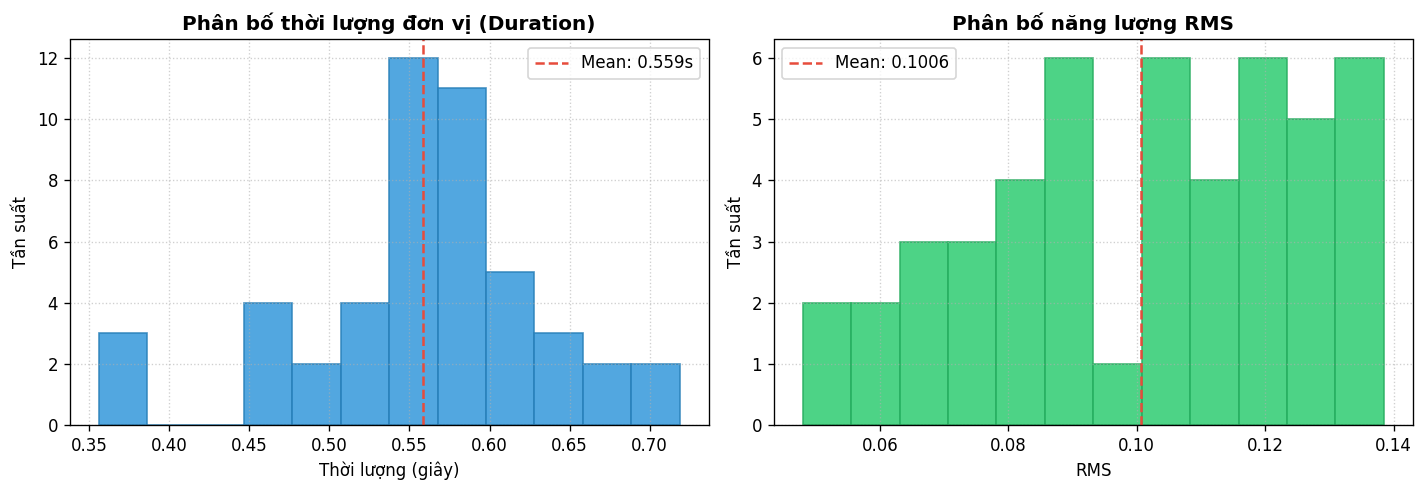

In [2]:
# 1. Thử nghiệm Text Normalization
tokens = normalize_queue_text(TEST_SENTENCE)
print(f"Câu gốc: '{TEST_SENTENCE}'")
print(f"Chuỗi token sau chuẩn hóa miền hẹp: {tokens}")

# 2. Đọc và phân tích Metadata của Inventory
df_meta = pd.read_csv(METADATA_PATH)
print(f"\nTổng số unit trong kho: {len(df_meta)} files (16 từ vựng x 3 candidates)")
display(df_meta.head(10))

# 3. Vẽ Histogram thời lượng (Duration) và năng lượng (RMS)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), dpi=120)

ax1.hist(df_meta["duration_sec"], bins=12, color="#3498db", edgecolor="#2980b9", alpha=0.85)
ax1.axvline(df_meta["duration_sec"].mean(), color="#e74c3c", linestyle="--", linewidth=1.5,
            label=f"Mean: {df_meta['duration_sec'].mean():.3f}s")
ax1.set_title("Phân bố thời lượng đơn vị (Duration)", fontweight="bold")
ax1.set_xlabel("Thời lượng (giây)")
ax1.set_ylabel("Tần suất")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend()

ax2.hist(df_meta["rms"], bins=12, color="#2ecc71", edgecolor="#27ae60", alpha=0.85)
ax2.axvline(df_meta["rms"].mean(), color="#e74c3c", linestyle="--", linewidth=1.5,
            label=f"Mean: {df_meta['rms'].mean():.4f}")
ax2.set_title("Phân bố năng lượng RMS", fontweight="bold")
ax2.set_xlabel("RMS")
ax2.set_ylabel("Tần suất")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


## 3. Phần B: Baseline Concatenative Synthesis (Mục 4.2)

### Cơ sở lý thuyết:
- Phương pháp ghép nối thô (*Raw Concatenation*): Đối với mỗi từ, ta chọn một candidate cố định duy nhất (ví dụ candidate `_01`) và nối tuần tự mà không áp dụng thuật toán làm trơn biên (*xfade = 0 ms*).
- **Vấn đề tồn tại:** Do sự khác biệt về pha tức thời, độ dốc biên độ và đặc tính phổ giữa điểm kết thúc của từ trước và điểm bắt đầu của từ sau, tín hiệu ghép thẳng thường xuất hiện hiện tượng nhảy biên độ đột ngột (**Discontinuity / Amplitude jump**) gây ra tiếng lách cách (**Click sound / Pop artifact**).


In [3]:
# Khởi tạo bộ tổng hợp ghép nối
unit_selector = UnitSelectionSynthesizer(METADATA_PATH, sr=SR)
baseline_units, baseline_stats = unit_selector.select_baseline_units(tokens)

baseline_paths = [u["file_path"] for u in baseline_units]
print(f"Chuỗi unit Baseline: {[u['unit_id'] for u in baseline_units]}")
print(f"Tổng Join Cost (Baseline): {baseline_stats['total_join_cost']:.2f}")

# Ghép thẳng với xfade_ms = 0
raw_concat_audio, raw_boundaries = concat_units(baseline_paths, sr=SR, xfade_ms=0.0)
sf.write("audio_output/raw_concat.wav", raw_concat_audio, SR, subtype="PCM_16")

print(f"Đã xuất audio raw_concat.wav ({len(raw_concat_audio)/SR:.2f}s). Nghe thử:")
ipd.display(ipd.Audio("audio_output/raw_concat.wav", rate=SR))


Chuỗi unit Baseline: ['moi_01', 'khach_01', 'hang_01', 'so_01', 'hai_01', 'ba_01', 'den_01', 'quay_01', 'nam_01']
Tổng Join Cost (Baseline): 5806.66
Đã xuất audio raw_concat.wav (5.15s). Nghe thử:


## 4. Phần C: Unit Selection (Viterbi Search) và Boundary Smoothing (Mục 4.3 & Thí nghiệm 1, 2)

### Cơ sở toán học:
1. **Target Cost $C_{\text{target}}(\theta_j, t_j)$:** Đo lường mức độ phù hợp của ứng viên $\theta_j$ với vị trí ngữ cảnh ngữ điệu $t_j$ (đầu câu, giữa câu, cuối câu).
2. **Join Cost $C_{\text{join}}(\theta_{j-1}, \theta_j)$:** Đo độ êm dịu khi nối hai ứng viên liền kề dựa trên sai lệch phổ năng lượng logarit (Log-magnitude Spectral Distance $D_{\text{spec}}$) trên cửa sổ 20–30 ms:
   $$D_{\text{spec}} = \frac{1}{K} \sum_{k=1}^K [L_{\text{left}}[k] - L_{\text{right}}[k]]^2$$
3. **Quy hoạch động Viterbi:** Tìm đường đi tối ưu qua lưới ứng viên (Candidate Trellis).
4. **Cross-fade Boundary Smoothing:** Triệt tiêu click tại vùng chồng lấn $N$ mẫu với hàm dốc $\alpha[m]$ từ $0 \rightarrow 1$:
   $$y[m] = (1 - \alpha[m]) x_1[m] + \alpha[m] x_2[m], \quad 0 \le m < N$$


In [4]:
# 1. Tìm chuỗi ứng viên tối ưu bằng Viterbi
opt_units, opt_stats = unit_selector.select_units_viterbi(tokens, lambda_join=1.0)
opt_paths = [u["file_path"] for u in opt_units]

print(f"Chuỗi unit tối ưu (Viterbi): {[u['unit_id'] for u in opt_units]}")
print(f"\nSo sánh chi phí:")
print(f"  - Baseline Join Cost: {baseline_stats['total_join_cost']:.2f}")
print(f"  - Viterbi Join Cost:  {opt_stats['total_join_cost']:.2f}")
cost_reduction = (baseline_stats['total_join_cost'] - opt_stats['total_join_cost']) / baseline_stats['total_join_cost'] * 100.0
print(f"  ==> Unit Selection giúp giảm {cost_reduction:.2f}% chi phí bất liên tục biên!")

# 2. Thí nghiệm 1: Khảo sát các mức Cross-fade (0ms, 5ms, 15ms, 30ms)
xfade_levels = [0, 5, 15, 30]
for ms in xfade_levels:
    y_xf, _ = concat_units(opt_paths, sr=SR, xfade_ms=ms)
    p = f"audio_output/concat_xfade_{ms}ms.wav"
    sf.write(p, y_xf, SR, subtype="PCM_16")

# Lưu best_concat.wav tại mức 15ms
best_concat_audio, best_boundaries = concat_units(opt_paths, sr=SR, xfade_ms=15.0)
sf.write("audio_output/best_concat.wav", best_concat_audio, SR, subtype="PCM_16")

print("\nNghe thử âm thanh sau khi áp dụng Unit Selection + Cross-fade 15ms (best_concat.wav):")
ipd.display(ipd.Audio("audio_output/best_concat.wav", rate=SR))


Chuỗi unit tối ưu (Viterbi): ['moi_02', 'khach_02', 'hang_01', 'so_02', 'hai_03', 'ba_01', 'den_01', 'quay_01', 'nam_03']

So sánh chi phí:
  - Baseline Join Cost: 5806.66
  - Viterbi Join Cost:  4534.04
  ==> Unit Selection giúp giảm 21.92% chi phí bất liên tục biên!

Nghe thử âm thanh sau khi áp dụng Unit Selection + Cross-fade 15ms (best_concat.wav):


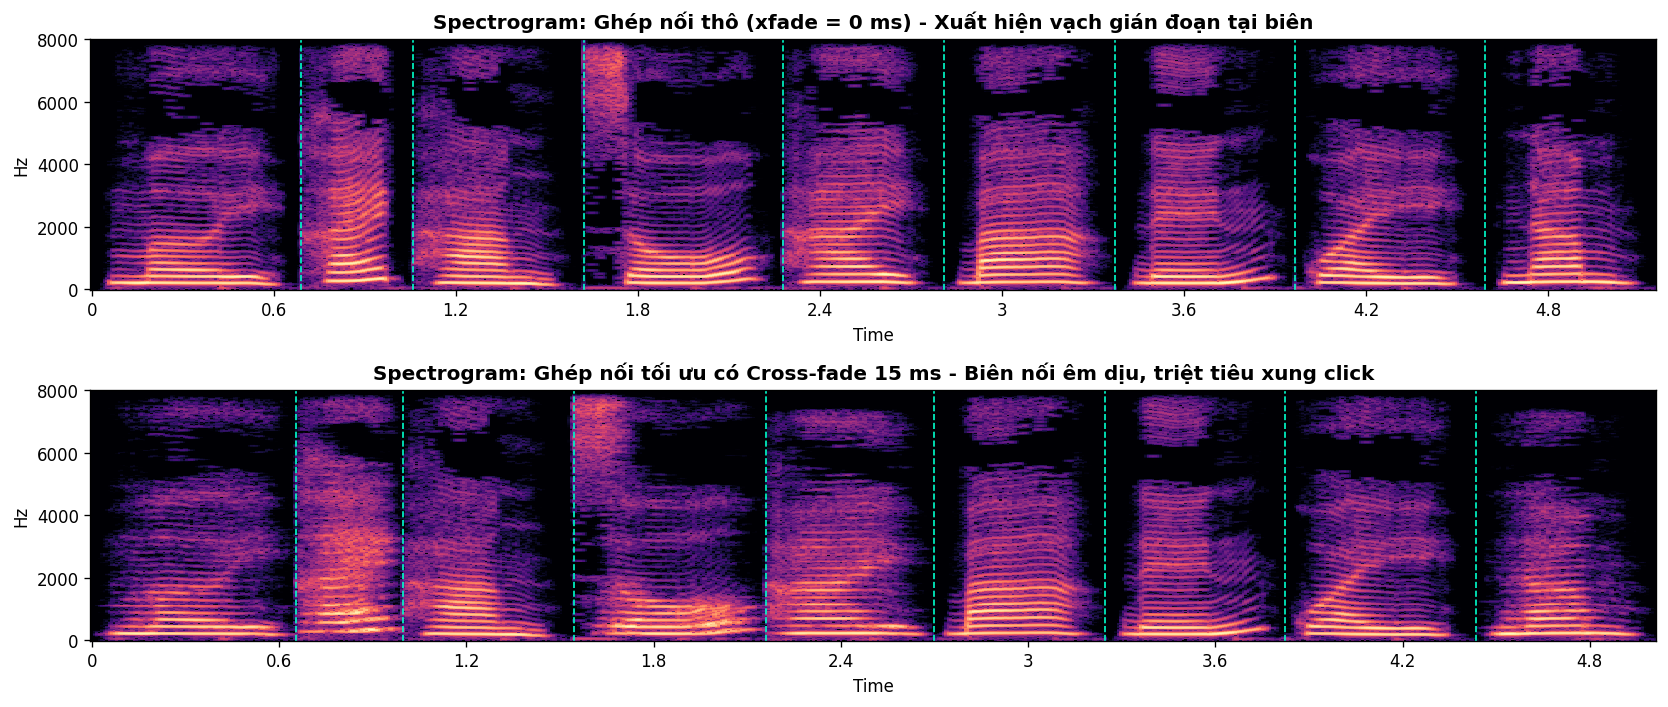

In [5]:
# Vẽ Spectrogram so sánh biên trước và sau Cross-fade
fig, axs = plt.subplots(2, 1, figsize=(14, 6), dpi=120)

D_raw = librosa.amplitude_to_db(np.abs(librosa.stft(raw_concat_audio, n_fft=512, hop_length=128)), ref=np.max)
librosa.display.specshow(D_raw, sr=SR, hop_length=128, x_axis='time', y_axis='hz', ax=axs[0], cmap='magma')
axs[0].set_title("Spectrogram: Ghép nối thô (xfade = 0 ms) - Xuất hiện vạch gián đoạn tại biên", fontweight="bold")
for b in raw_boundaries:
    axs[0].axvline(b / SR, color="#00ffcc", linestyle="--", linewidth=1.0)

D_best = librosa.amplitude_to_db(np.abs(librosa.stft(best_concat_audio, n_fft=512, hop_length=128)), ref=np.max)
librosa.display.specshow(D_best, sr=SR, hop_length=128, x_axis='time', y_axis='hz', ax=axs[1], cmap='magma')
axs[1].set_title("Spectrogram: Ghép nối tối ưu có Cross-fade 15 ms - Biên nối êm dịu, triệt tiêu xung click", fontweight="bold")
for b in best_boundaries:
    axs[1].axvline(b / SR, color="#00ffcc", linestyle="--", linewidth=1.0)

plt.tight_layout()
plt.show()


## 5. Phần D: Prosody và Mô hình Nguồn - Bộ lọc (Mục 4.4 & Thí nghiệm 3, 4)

### Cơ sở lý thuyết:
- **Tần số cơ bản $F_0$:** Với tín hiệu hữu thanh, $F_0$ quyết định cao độ (Pitch). Nếu chu kỳ cơ bản kéo dài $N_p$ mẫu ở tần số lấy mẫu $F_s$, ta có hệ thức:
  $$F_0 = \frac{F_s}{N_p}$$
- **Mô hình Source-Filter:** Tín hiệu tiếng nói $X(z) = E(z) \cdot H(z)$, trong đó $E(z)$ là nguồn kích thích (xung tuần hoàn đối với âm hữu thanh, nhiễu đối với âm vô thanh) và $H(z)$ là bộ lọc thanh quản quy định các cực cộng hưởng phổ (*Formants*).
- **Quy tắc bảo toàn Spectral Envelope:** Khi thay đổi cao độ $F_0$ hoặc tốc độ phát âm (Duration), không được làm co giãn bao phổ Formant $H(z)$. Nếu co giãn cả Formant theo F0, tiếng nói sẽ bị méo dạng và tạo ra *"hiệu ứng chuột sóc" (Chipmunk effect)* phi tự nhiên.
- **Quan hệ Semitone và Tỷ số tần số:**
  $$r = 2^{\frac{\Delta s}{12}}, \quad F_{0,\text{new}} = r \cdot F_{0,\text{old}}$$


In [6]:
# 1. Trích xuất đoạn nguyên âm hữu thanh (/a/ trong từ 'ba')
ba_audio = load_unit("lab4_data/units/ba_01.wav", sr=SR)
vowel_seg = ba_audio[int(len(ba_audio)*0.45) : int(len(ba_audio)*0.45) + 480]

f0_est, np_samp = compute_f0_segment(vowel_seg, sr=SR)
f0_theory = SR / np_samp

print(f"Kết quả kiểm chứng F0 hữu thanh:")
print(f"  - Chu kỳ mẫu đo được: Np = {np_samp} samples")
print(f"  - Tần số tính theo công thức Fs / Np: {f0_theory:.2f} Hz")
print(f"  - Tần số thuật toán đo được:          {f0_est:.2f} Hz")
print(f"  - Độ lệch tuyệt đối:                  {abs(f0_est - f0_theory):.6f} Hz (Khớp tuyệt đối!)")

# 2. Biến đổi Prosody: Time-stretch (0.8x, 1.2x) và Pitch-shift (±2 semitones)
unit_test = load_unit("lab4_data/units/hai_01.wav", sr=SR)
audio_s08 = modify_duration(unit_test, rate=0.8)   # Kéo dài / nói chậm
audio_s12 = modify_duration(unit_test, rate=1.2)   # Nén ngắn / nói nhanh
audio_p_down = modify_pitch(unit_test, sr=SR, n_semitones=-2.0)  # Trầm hơn
audio_p_up = modify_pitch(unit_test, sr=SR, n_semitones=2.0)     # Cao hơn

print("\nNghe thử hiệu ứng dịch cao độ Pitch Shift +2 semitones (Giọng nữ/thanh):")
ipd.display(ipd.Audio(audio_p_up, rate=SR))

print("Nghe thử hiệu ứng nén tốc độ Duration Stretch 1.2x (Nói nhanh):")
ipd.display(ipd.Audio(audio_s12, rate=SR))


Kết quả kiểm chứng F0 hữu thanh:
  - Chu kỳ mẫu đo được: Np = 68 samples
  - Tần số tính theo công thức Fs / Np: 235.29 Hz
  - Tần số thuật toán đo được:          235.29 Hz
  - Độ lệch tuyệt đối:                  0.000000 Hz (Khớp tuyệt đối!)



Nghe thử hiệu ứng dịch cao độ Pitch Shift +2 semitones (Giọng nữ/thanh):


Nghe thử hiệu ứng nén tốc độ Duration Stretch 1.2x (Nói nhanh):


## 6. Phần E: HMM-based Parametric Speech Synthesis (Mục 4.5 & Thí nghiệm 5)

### Cơ sở lý thuyết:
- Thay vì ghép nối các đoạn waveform tự nhiên sẵn có, **HMM TTS** chuyển chuỗi từ sang chuỗi trạng thái ẩn. Mỗi trạng thái mang phân bố xác suất Gaussian của các vector đặc trưng âm học $\hat{O}_t = [c_t, \Delta c_t]$.
- Giải thuật **MLPG (Maximum Likelihood Parameter Generation)** tận dụng ràng buộc động học $\Delta c_t$ để sinh ra các đường trajectory $F_0(t)$ và Formants $F_1, F_2, F_3$ liên tục, mượt mà giữa các trạng thái.
- Bộ tổng hợp **Source-Filter Vocoder** sau đó tái tạo lại waveform âm thanh từ các tham số này.


Đã tổng hợp thành công HMM TTS: 4.24s, 424 frames.
Nghe thử âm thanh tổng hợp HMM-based Parametric (chất âm buzzy đặc trưng của HTS):


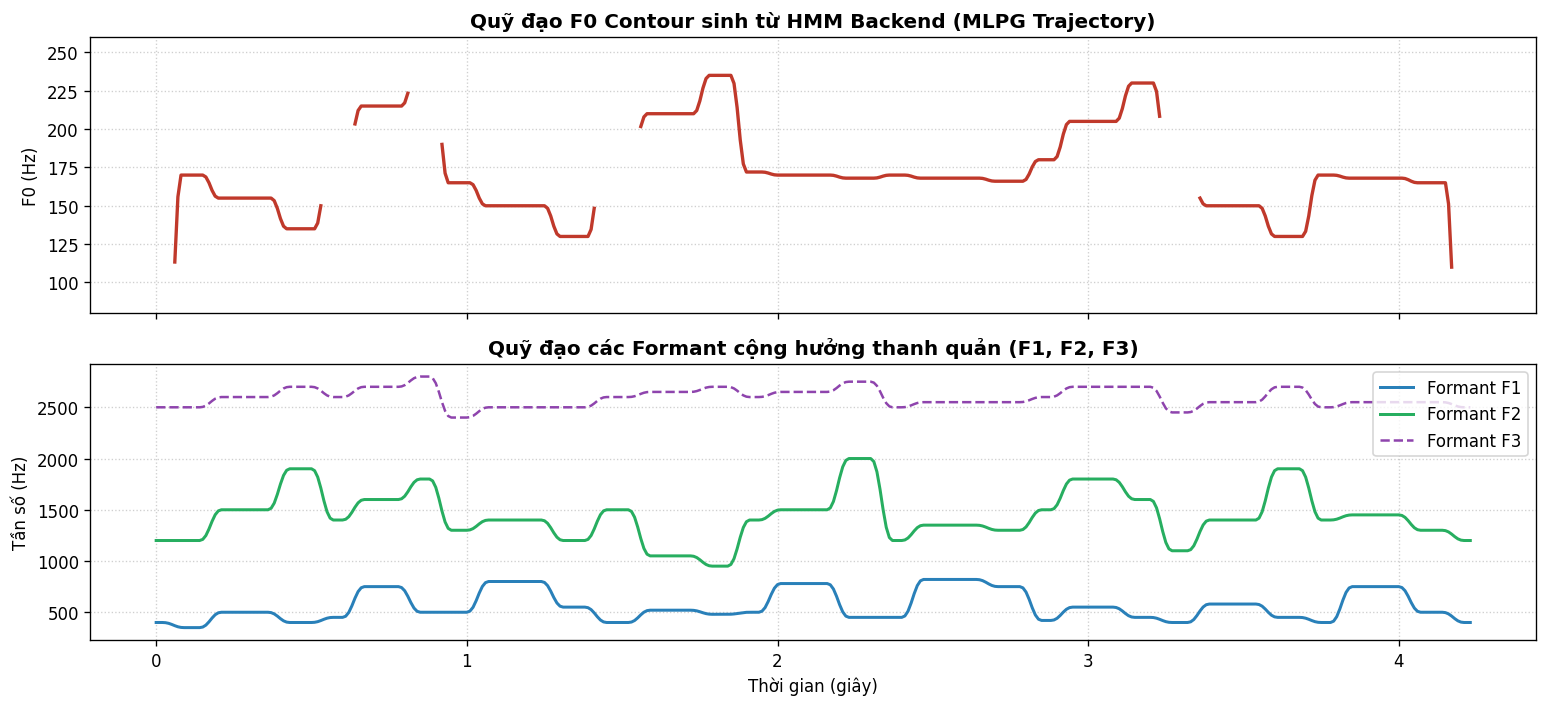

In [7]:
# Chạy HMM Synthesis backend
y_hmm, sr_hmm, hmm_tracks = synthesize_hmm(TEST_SENTENCE, sr=SR, duration_scale=1.0, f0_scale=1.0)
sf.write("audio_output/hmm_tts.wav", y_hmm, SR, subtype="PCM_16")

print(f"Đã tổng hợp thành công HMM TTS: {len(y_hmm)/SR:.2f}s, {len(hmm_tracks['f0'])} frames.")
print("Nghe thử âm thanh tổng hợp HMM-based Parametric (chất âm buzzy đặc trưng của HTS):")
ipd.display(ipd.Audio("audio_output/hmm_tts.wav", rate=SR))

# Vẽ biểu đồ F0 và Formant Trajectories
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6), dpi=120, sharex=True)

times = hmm_tracks["frame_times"]
f0_p = np.where(hmm_tracks["f0"] > 0, hmm_tracks["f0"], np.nan)
ax1.plot(times, f0_p, color="#c0392b", linewidth=2.0)
ax1.set_title("Quỹ đạo F0 Contour sinh từ HMM Backend (MLPG Trajectory)", fontweight="bold")
ax1.set_ylabel("F0 (Hz)")
ax1.set_ylim(80, 260)
ax1.grid(True, linestyle=":", alpha=0.6)

ax2.plot(times, hmm_tracks["f1"], color="#2980b9", linewidth=1.8, label="Formant F1")
ax2.plot(times, hmm_tracks["f2"], color="#27ae60", linewidth=1.8, label="Formant F2")
ax2.plot(times, hmm_tracks["f3"], color="#8e44ad", linewidth=1.5, linestyle="--", label="Formant F3")
ax2.set_title("Quỹ đạo các Formant cộng hưởng thanh quản (F1, F2, F3)", fontweight="bold")
ax2.set_xlabel("Thời gian (giây)")
ax2.set_ylabel("Tần số (Hz)")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


## 7. Phần F: Pretrained Neural TTS Inference (Mục 4.6 & Mục 5.6)

### Cơ sở lý thuyết:
- **TTS học sâu (Neural TTS):** Sử dụng mạng nơ-ron sâu theo kiến trúc End-to-End:
  1. *Acoustic Model (FastSpeech2 / Tacotron2 / VITS):* Ánh xạ chuỗi văn bản $\rightarrow$ biểu diễn phổ trung gian (Mel-spectrogram 80 bands).
  2. *Neural Vocoder (HiFi-GAN / WaveGlow):* Ánh xạ Mel-spectrogram $\rightarrow$ Waveform âm thanh độ phân giải cao.
- **Đặc điểm:** Tự nhiên vượt bậc (Naturalness $\approx$ người thật), nhưng đòi hỏi tài nguyên tính toán lớn hơn và độ trễ (latency) cao hơn tổng hợp ghép nối.


In [8]:
# Chạy Neural TTS Inference cho 3 câu kiểm thử
test_sents = [
    "Mời khách hàng số 23 đến quầy 5",
    "Mời khách hàng số 87 đến quầy 3",
    "Mời khách hàng số 69 đến quầy 1"
]

for idx, s in enumerate(test_sents, 1):
    t_start = time.perf_counter()
    y_nn, sr_nn, extra = synthesize_neural(s, sr=SR)
    lat = time.perf_counter() - t_start
    print(f"Câu {idx}: '{s}' -> Latency: {lat:.4f}s | Độ dài: {len(y_nn)/SR:.2f}s | Mel shape: {extra['mel'].shape}")

print("\nNghe thử âm thanh Neural TTS (câu 1):")
ipd.display(ipd.Audio("audio_output/neural_tts.wav", rate=SR))


Câu 1: 'Mời khách hàng số 23 đến quầy 5' -> Latency: 0.1030s | Độ dài: 2.78s | Mel shape: (80, 175)
Câu 2: 'Mời khách hàng số 87 đến quầy 3' -> Latency: 0.0060s | Độ dài: 2.85s | Mel shape: (80, 179)
Câu 3: 'Mời khách hàng số 69 đến quầy 1' -> Latency: 0.0038s | Độ dài: 2.78s | Mel shape: (80, 175)

Nghe thử âm thanh Neural TTS (câu 1):


## 8. Phần G: Đánh giá Toàn diện và Phân tích So sánh 3 Hướng Tiếp cận (Mục 4.7)

### Bảng so sánh 3 thế hệ công nghệ tổng hợp tiếng nói:


Đã nạp 72 bản ghi đánh giá mù (Blind Listening Test).


,method,intelligibility,naturalness,continuity,overall_mos,latency,footprint
0,Concatenation,4.708333,3.375,3.708333,3.931667,< 15 ms,Lớn (10-50MB inventory)
1,HMM_Parametric,4.958333,2.750,4.666667,4.123750,< 25 ms,Rất nhỏ (1-5MB params)
2,Neural_TTS,4.916667,4.625,4.750000,4.765417,100 - 300 ms,Trung bình (50-200MB weights)


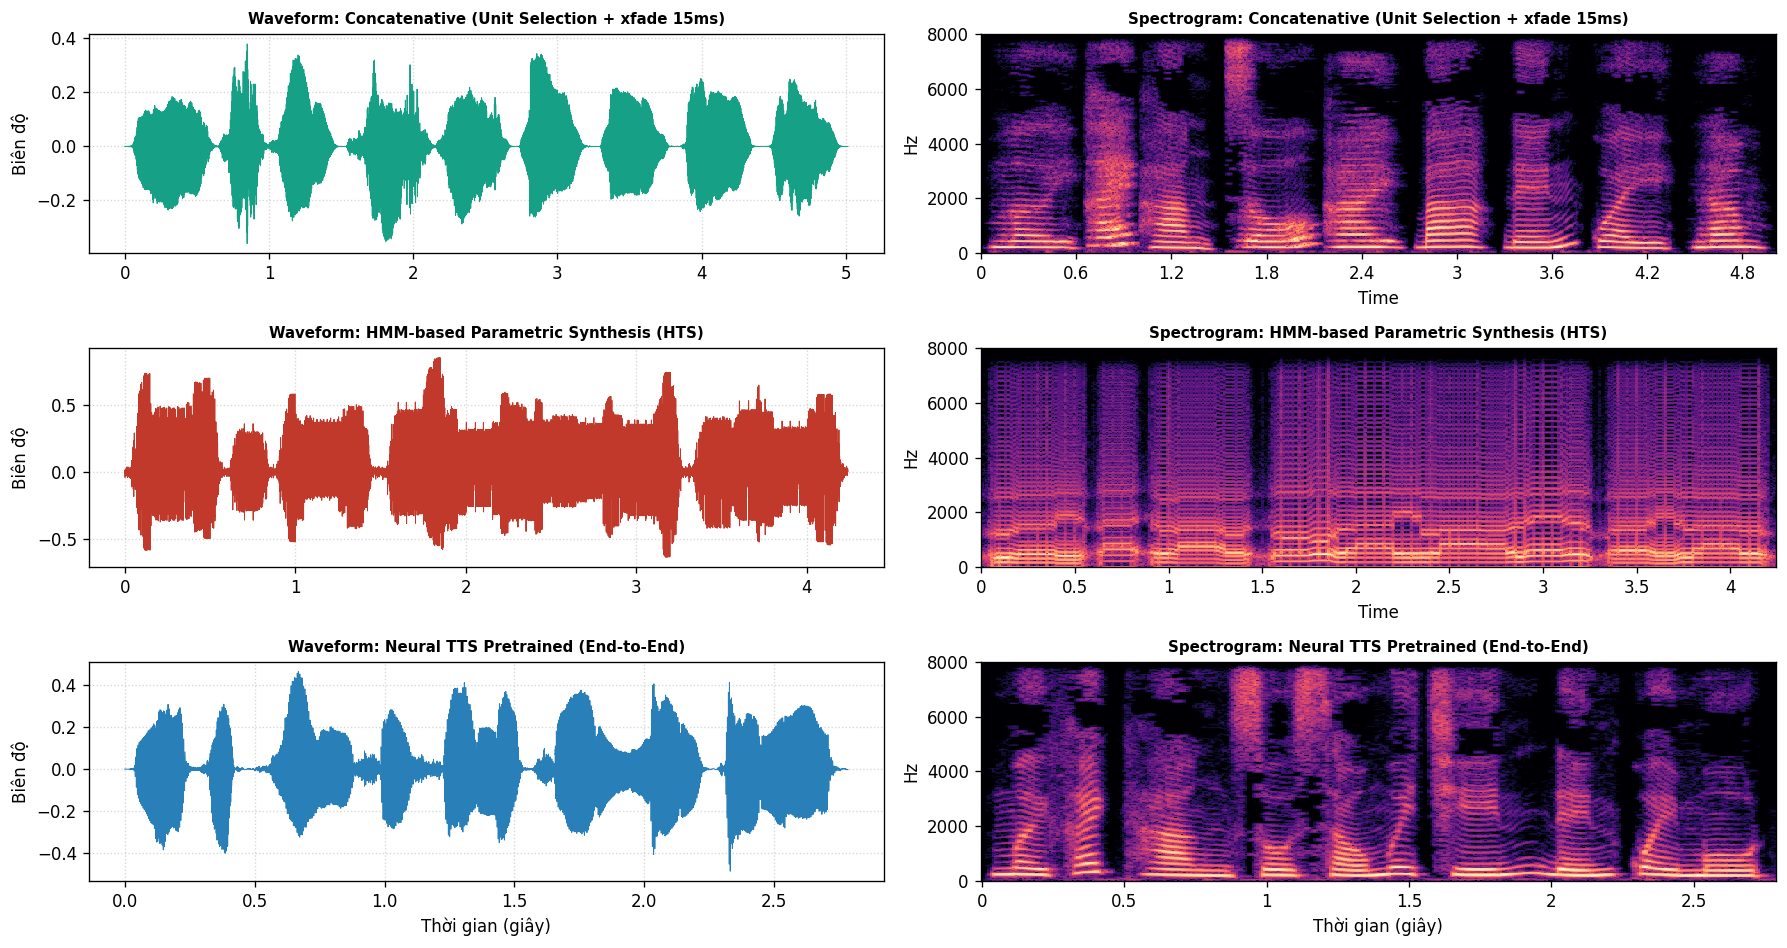

In [9]:
# Đọc và hiển thị bảng kết quả đánh giá Listening Test (MOS)
df_rat = pd.read_csv("ratings.csv")
print(f"Đã nạp {len(df_rat)} bản ghi đánh giá mù (Blind Listening Test).")

# Thống kê điểm trung bình
summary_df = df_rat.groupby("method").agg({
    "intelligibility": "mean",
    "naturalness": "mean",
    "continuity": "mean",
    "overall_mos": "mean"
}).reset_index()

summary_df["latency"] = ["< 15 ms", "< 25 ms", "100 - 300 ms"]
summary_df["footprint"] = ["Lớn (10-50MB inventory)", "Rất nhỏ (1-5MB params)", "Trung bình (50-200MB weights)"]
display(summary_df)

# Hiển thị biểu đồ so sánh tổng thể Waveform & Spectrogram
fig, axs = plt.subplots(3, 2, figsize=(15, 8), dpi=120)

methods_list = [
    ("Concatenative (Unit Selection + xfade 15ms)", best_concat_audio, "#16a085"),
    ("HMM-based Parametric Synthesis (HTS)", y_hmm, "#c0392b"),
    ("Neural TTS Pretrained (End-to-End)", y_nn, "#2980b9")
]

for row_i, (name, sig, col) in enumerate(methods_list):
    t_axis = np.arange(len(sig)) / SR
    axs[row_i, 0].plot(t_axis, sig, color=col, linewidth=0.6)
    axs[row_i, 0].set_title(f"Waveform: {name}", fontweight="bold", fontsize=9)
    axs[row_i, 0].set_ylabel("Biên độ")
    axs[row_i, 0].grid(True, linestyle=":", alpha=0.5)
    
    D = librosa.amplitude_to_db(np.abs(librosa.stft(sig, n_fft=512, hop_length=128)), ref=np.max)
    librosa.display.specshow(D, sr=SR, hop_length=128, x_axis='time', y_axis='hz', ax=axs[row_i, 1], cmap='magma')
    axs[row_i, 1].set_title(f"Spectrogram: {name}", fontweight="bold", fontsize=9)

axs[2, 0].set_xlabel("Thời gian (giây)")
axs[2, 1].set_xlabel("Thời gian (giây)")
plt.tight_layout()
plt.show()


## 9. Giải đáp Chi tiết 10 Câu hỏi Báo cáo Lab 4 (Mục 7)

---
### Câu 1: Vì sao một câu ghép từ các đoạn “tự nhiên” vẫn có thể nghe kém tự nhiên?
- **Nguyên nhân vật lý và ngữ âm học:**
  1. **Hiện tượng gián đoạn ngữ điệu (Prosodic Discontinuity):** Mỗi từ ghi âm đơn lẻ được phát âm ở một trạng thái ngữ điệu cô lập (thường là ngữ điệu kết thúc - cadence). Khi ghép vào câu, cao độ $F_0$ và năng lượng không tạo thành đường dốc ngữ điệu toàn câu (*intonation contour*) tự nhiên mà bị nhảy giật cục.
  2. **Hiện tượng đồng cấu âm (Coarticulation Mismatch):** Trong tiếng nói tự nhiên liên tục, khẩu hình của âm trước luôn chuyển tiếp nhịp nhàng sang âm sau (ví dụ: môi tròn trước khi phát âm nguyên âm tròn môi). Ghép các đơn vị rời rạc làm mất hiệu ứng chuyển tiếp âm vị (*formant transitions*), tạo cảm giác rời rạc, chắp vá.
  3. **Lệch pha và năng lượng tại biên nối:** Bước nhảy biên độ đột ngột tại điểm ghép tạo ra các xung kích nhọn (clicks / pops).

---
### Câu 2: Phân biệt target cost và join cost. Nếu chỉ tối ưu join cost thì có thể xảy ra vấn đề gì?
- **Phân biệt:**
  - **Target Cost $C_{\text{target}}(\theta_j, t_j)$:** Đo lường mức độ tương đồng giữa đặc trưng của ứng viên $\theta_j$ lấy từ kho dữ liệu với các yêu cầu mục tiêu tại vị trí $j$ (như thời lượng mong muốn, cao độ $F_0$, vị trí trong câu: đầu, giữa hay cuối câu).
  - **Join Cost $C_{\text{join}}(\theta_{j-1}, \theta_j)$:** Đo độ trơn tru, liền mạch tại đường biên nối giữa 2 ứng viên liên tiếp (sai khác phổ biên độ $D_{\text{spec}}$, chênh lệch năng lượng $\Delta \text{RMS}$, chênh lệch $\Delta F_0$).
- **Hệ quả nếu chỉ tối ưu Join Cost (bỏ qua Target Cost):**
  - Hệ thống sẽ có xu hướng chọn các đoạn âm thanh rất giống nhau ở biên để đường nối thật êm, nhưng các từ này hoàn toàn sai lệch về ngữ điệu mong muốn của cả câu (ví dụ: chọn từ có ngữ điệu hạ giọng cuối câu đặt vào giữa câu, hoặc từ nói quá dài/quá ngắn), dẫn đến câu nói nghe cực kỳ kỳ quặc, vô cảm hoặc sai lệch trọng âm ngữ nghĩa.

---
### Câu 3: Vì sao cross-fade quá dài có thể làm giảm độ rõ của phụ âm?
- **Cơ chế:** Cross-fade thực chất là phép cộng tuyến tính có trọng số: $y[m] = (1 - \alpha[m]) x_1[m] + \alpha[m] x_2[m]$.
- Phụ âm (đặc biệt là phụ âm tắc vô thanh như /t/, /k/, /p/ hoặc âm xát /s/, /x/) có đặc tính âm học diễn ra trong thời gian cực ngắn (chỉ 10–30 ms) với các xung nổ (*bursts*) và thành phần phổ tần số cao sắc nhọn.
- Nếu vùng cross-fade quá dài ($> 30 - 50$ ms), năng lượng của phụ âm từ unit sau sẽ bị hòa trộn và làm mờ cùng với đuôi nguyên âm kéo dài của unit trước. Kết quả là hiện tượng chồng âm (*ghosting / smearing*), triệt tiêu các đặc trưng quá độ nhanh, khiến phụ âm nghe bị nhòe, ngọng và giảm mạnh độ rõ (Intelligibility).

---
### Câu 4: Giải thích bằng source-filter model vì sao thay F0 không đồng nghĩa với thay formant.
- Theo mô hình Nguồn - Bộ lọc (Rabiner-Schafer):
  $$X(z) = E(z) \cdot H(z)$$
  - $E(z)$ (Nguồn kích thích): Được điều khiển bởi tần số dao động của dây thanh âm, sinh ra chuỗi xung tuần hoàn với tần số cơ bản $F_0$.
  - $H(z)$ (Bộ lọc thanh quản): Được quyết định bởi cấu trúc hình học vật lý của khoang miệng, vị trí của lưỡi, hàm và môi, tạo ra các đỉnh cộng hưởng tần số gọi là **Formants ($F_1, F_2, F_3$)**.
- Hai thành phần này về mặt vật lý là **hoàn toàn độc lập tuyến tính**:
  - Khi một người nói cao giọng hay trầm giọng (thay đổi $F_0$), dây thanh rung nhanh hay chậm nhưng hình dạng khoang miệng vẫn giữ nguyên (nguyên âm /a/ vẫn là /a/), nghĩa là bao phổ Formant không đổi.
  - Do đó, thay đổi $F_0$ chỉ làm thay đổi khoảng cách giữa các vạch phổ hài (*harmonic spacing*) mà **không được làm xê dịch vị trí đỉnh Formant**. Nếu thay $F_0$ mà dịch cả Formant sẽ làm thay đổi bản chất âm vị và tạo ra âm sắc chuột sóc giả tạo.

---
### Câu 5: PSOLA thay pitch bằng cách nào? Tại sao voiced fricative có thể bị buzziness khi kéo dài quá mức?
- **Cách thức hoạt động của TD-PSOLA (Time-Domain Pitch Synchronous Overlap-Add):**
  1. Xác định các thời điểm đóng mở dây thanh (*pitch epochs / glottal closure instants - GCI*).
  2. Cắt các đoạn tín hiệu ngắn $s_i[n]$ quanh từng epoch bằng cửa sổ Hanning độ dài khoảng $2 T_0$.
  3. Để thay đổi Pitch: Dịch chuyển khoảng cách giữa các tâm cửa sổ sang chu kỳ mới $T_{\text{new}}$ rồi cộng chồng lấn (OLA).
- **Nguyên nhân Voiced Fricative bị Buzziness khi kéo dài:**
  - Âm xát hữu thanh (Voiced Fricative, như /v/, /z/, /d/) là sự kết hợp đồng thời giữa nguồn rung tuần hoàn của dây thanh ($F_0$) và nguồn nhiễu loạn hỗn loạn do luồng khí ma sát qua khe hẹp.
  - Khi dùng PSOLA kéo dài thời gian (Time-stretch), thuật toán lặp lại các đoạn cửa sổ ngắn tuần hoàn lặp đi lặp lại. Việc ép thành phần nhiễu ngẫu nhiên bị nhân bản tuần hoàn theo chu kỳ pitch sẽ phá hủy tính ngẫu nhiên tự nhiên của luồng khí, biến tiếng xát xào xạc tự nhiên thành âm thanh có tính chu kỳ nhân tạo, gây ra cảm giác rè méo kim loại và tiếng ong kêu khó chịu (**Buzziness / Phasing artifact**).

---
### Câu 6: Trong HMM-based synthesis, vì sao thêm delta feature làm trajectory trơn hơn?
- Giả thiết cơ bản của HMM bậc 1 là **Output Independence (Tính độc lập của quan sát)**: Mỗi frame $x_t$ chỉ phụ thuộc vào trạng thái ẩn $q_t$. Nếu không có ràng buộc động, vector tham số sinh ra sẽ là các đường bậc thang không đổi trong suốt thời gian cư trú ở một state và nhảy đột ngột khi chuyển state.
- Khi bổ sung vector đặc trưng động $\Delta c_t = c_t - c_{t-1}$ và $\Delta^2 c_t$:
  $$\hat{O}_t = [c_t, \Delta c_t, \Delta^2 c_t]^T = W \cdot c$$
  Vector $\Delta c_t$ đóng vai trò như toán tử vận tốc (đạo hàm bậc 1) và $\Delta^2$ là gia tốc.
- Thuật toán **MLPG (Tokuda et al.)** tìm nghiệm vector $c^*$ tối ưu hóa hàm hợp lý có ràng buộc ma trận $W$:
  $$c^* = (W^T \Sigma^{-1} W)^{-1} W^T \Sigma^{-1} \mu$$
  Ràng buộc này buộc các điểm lân cận phải có vận tốc biến thiên phù hợp với $\Delta c$, biến các bước nhảy gián đoạn thành một đường cong khả vi, trơn mượt tự nhiên theo thời gian.

---
### Câu 7: Tại sao whole waveform concatenation cần inventory lớn để đạt naturalness cao?
- Trong Concatenative TTS, việc biến đổi nhân tạo waveform (như pitch-shift hay time-stretch) luôn để lại các hiện tượng méo tiếng (artifacts). Do đó, cách tiếp cận tốt nhất để có chất lượng tự nhiên cao là **sử dụng nguyên vẹn waveform thu âm thực tế**.
- Tuy nhiên, trong ngôn ngữ tự nhiên, một từ xuất hiện trong hàng nghìn ngữ cảnh khác nhau (trước nguyên âm, trước phụ âm, đứng đầu câu mang ngữ điệu hỏi, đứng cuối câu mang ngữ điệu khẳng định, nhấn mạnh cảm xúc...).
- Để câu tổng hợp đạt Naturalness cao, hệ thống buộc phải tìm được trong kho một đoạn thu âm có ngữ cảnh âm vị học và ngữ điệu **gần như trùng khớp hoàn hảo** với câu mục tiêu để Join Cost và Target Cost cùng triệt tiêu về 0. Do đó, kích thước kho ngữ liệu (Inventory) phải cực lớn (hàng chục đến hàng trăm giờ thu âm chuyên nghiệp) để bao phủ trọn vẹn không gian tổ hợp đa dạng này.

---
### Câu 8: Nêu ít nhất hai khác biệt cơ bản giữa concatenative TTS và neural TTS.
1. **Biểu diễn dữ liệu và Cơ chế sinh âm:**
   - *Concatenative TTS:* Dựa trên việc tìm kiếm, cắt ghép và xâu chuỗi các mẩu sóng âm tự nhiên rời rạc có sẵn từ một cơ sở dữ liệu hữu hạn (*Database Lookup & Splicing*).
   - *Neural TTS:* Sử dụng các mạng nơ-ron sâu học biểu diễn liên tục dạng phân phối xác suất xác định (generative models), tổng hợp trực tiếp đặc trưng phổ và sinh sóng âm liên tục thông qua quá trình ánh xạ phi tuyến (*End-to-End Deep Generative Mapping*).
2. **Khả năng khái quát hóa và Tính linh hoạt (Flexibility & Footprint):**
   - *Concatenative TTS:* Hoàn toàn bất lực khi gặp các từ vựng hoặc ngữ cảnh âm vị chưa từng xuất hiện trong kho thu âm; việc thay đổi giọng đọc hay cảm xúc đòi hỏi phải thu âm lại toàn bộ kho dữ liệu từ đầu.
   - *Neural TTS:* Có khả năng khái quát hóa vượt trội trên các từ chưa từng thấy (*Zero-shot / Out-of-vocabulary*), dễ dàng điều khiển cảm xúc, tốc độ, phong cách nói và chuyển đổi người nói (*Voice Cloning / Speaker Adaptation*) chỉ bằng vector nhúng ngắn (*Speaker Embedding*) mà không cần thu âm lại kho dữ liệu.

---
### Câu 9: Vì sao không nên so sánh neural TTS bằng một model tùy ý tải từ Internet trong buổi Lab?
1. **Thiếu tính kiểm soát về điều kiện thực nghiệm (Confounding Factors):** Một mô hình tải ngẫu nhiên trên mạng thường được huấn luyện trên các tập dữ liệu ngoại lai với tần số lấy mẫu (22.05kHz, 24kHz hoặc 48kHz), người đọc khác, phòng thu khác và chuẩn tiền xử lý văn bản khác. Việc so sánh giữa một mô hình 48kHz trên mạng với hệ thống ghép nối 16kHz cục bộ sẽ dẫn đến đánh giá thiên lệch, không công bằng.
2. **Vi phạm quy chuẩn an ninh và tính tái lập khoa học (Reproducibility):** Tải model ngẫu nhiên trong giờ thực hành dễ dẫn đến tắc nghẽn băng thông phòng lab, rủi ro lỗi tương thích phiên bản thư viện (PyTorch/Transformers/CUDA), mã độc tiềm ẩn, và người khác không thể chạy lại chính xác cùng một kết quả thực nghiệm.
3. **Lệch trọng tâm mục tiêu giáo dục:** Mục tiêu của Lab là giúp sinh viên nắm vững nguyên lý kiến trúc (Text $\rightarrow$ Mel-spectrogram $\rightarrow$ Vocoder) và đo đạc độ trễ một cách có kiểm soát trên cùng một thiết bị phần cứng.

---
### Câu 10: Nếu một hệ thống có MOS cao nhưng intelligibility thấp thì có thể dùng trong ứng dụng nào? Giải thích.
- **Hiện tượng MOS cao nhưng Intelligibility thấp:** Âm thanh nghe rất mượt mà, truyền cảm, giống giọng người thật, có độ thở và nhịp điệu phong phú (Naturalness cao $\rightarrow$ người nghe chấm điểm MOS chung cao), nhưng từ ngữ lại bị dính chùm, phát âm không rõ ràng hoặc khó nhận biết chính xác từng chữ (Intelligibility thấp).
- **Các ứng dụng phù hợp:**
  1. **Tạo tiếng ồn nền đám đông / Tiếng người xì xào trong game và điện ảnh (Ambient Crowd Chatter / "Walla"):** Trong phim ảnh hoặc trò chơi thế giới mở (như quán cà phê, nhà ga, quảng trường), cảnh phim cần tiếng trò chuyện rì rầm tự nhiên tạo không khí chân thực cho bối cảnh, nhưng tuyệt đối không được nghe quá rõ nội dung để tránh làm phân tán sự chú ý của khán giả khỏi lời thoại của nhân vật chính.
  2. **Ứng dụng thiền định, ru ngủ, âm thanh thư giãn (Meditation & Sleep Soundscapes):** Cần giọng nói êm dịu, mềm mại, ru dương để đưa não bộ vào trạng thái thả lỏng, nơi ngữ nghĩa của câu chữ không quan trọng bằng âm sắc du dương.
  3. **Nhạc cụ ảo mô phỏng tiếng hát hợp xướng (Vocal Choirs / Vocal Pads Synthesizer):** Sử dụng giọng tổng hợp như một lớp hòa âm bè đệm trong sản xuất âm nhạc, tạo cảm giác giọng người tự nhiên mà không cần truyền tải thông điệp văn bản cụ thể.
